# *IT00CS34 Edge Computing for ML - Spring 26*



# Training using TensorFlow

## Overview

To effectively deploy deep neural models on resource-constrained edge devices, two critical aspects of model optimization are most useful: pruning, which involves reducing the size of a neural network by eliminating unnecessary parameters, and quantization, which involves reducing the precision of numerical values in the model to conserve memory and computational resources.

For using these techniques, we define the application area by employing a small CNN based-architecture trained on rock-paper-scissors dataset by Laurence Moroney. At the end of the notebook, we obtain the trained full-precision model to be used for the further steps of the project.

### Dataset overview
Rock Paper Scissors contains images from a variety of different hands, from different races, ages and genders, posed into Rock / Paper or Scissors and labelled as such. These images have all been generated using CGI techniques as an experiment in determining if a CGI-based dataset can be used for classification against real images.

Note that all of this data is posed against a white background.

Each image is 300×300 pixels in 24-bit color

## Setup

You may need to restart session in google colab after executing the following cell.

In [ ]:
! pip install --user --upgrade tensorflow-model-optimization

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 242.7/242.7 kB 7.1 MB/s eta 0:00:00


In [ ]:
import os
import tensorflow as tf
from tensorflow_model_optimization.python.core.keras.compat import keras
import numpy as np
import tensorflow_datasets as tfds
import matplotlib.pyplot as plt
tf.random.set_seed(
    seed=81
)

ModuleNotFoundError: No module named 'tensorflow_model_optimization'

## Using Tensorflow Datasets API to load MNIST

TFDS datasets often come with data already split into different sets. For rock_paper_scissors, it has splits for train and test. We use the [Slicing API](https://www.tensorflow.org/datasets/splits#slicing_api) for TFDS to create a validation split.

Next, we aim to understand how the dataset is formatted and utilize visualizations. Finally, the dataset is preprocessed before being passed to the model. For preprocessing, we rescale to a much smaller resolution, convert to grayscale and normalize the image values as float32 within the range [0, 1] for all three splits.

In [ ]:
(dataset_train, dataset_val, dataset_test), ds_info = tfds.load(
    'rock_paper_scissors',
    split=['train[:90%]', 'train[90%:]', 'test'],
    shuffle_files=True,
    as_supervised=True,
    with_info=True,
)

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Generating splits...:   0%|          | 0/2 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/rock_paper_scissors/incomplete.GSWL1I_3.0.0/rock_paper_scissors-train.tfre…

Generating test examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/rock_paper_scissors/incomplete.GSWL1I_3.0.0/rock_paper_scissors-test.tfrec…

Dataset rock_paper_scissors downloaded and prepared to /root/tensorflow_datasets/rock_paper_scissors/3.0.0. Subsequent calls will reuse this data.


Input image shape: (300, 300, 3)
Image type: <dtype: 'uint8'>
Label shape: ()
Label type: <dtype: 'int64'>


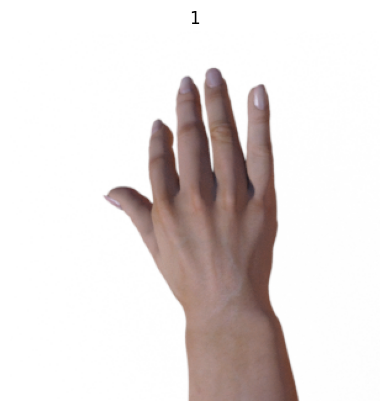

In [ ]:
ds = dataset_train.take(1)  # Only take a single example
for example in ds:  
  image = example[0]
  label = example[1]
  print(f"Input image shape: {image.shape}\nImage type: {image.dtype}")
  print(f"Label shape: {label.shape}\nLabel type: {label.dtype}")
  plt.imshow(image, cmap='gray')
  plt.title(label.numpy())
  plt.axis("off")
  plt.show()


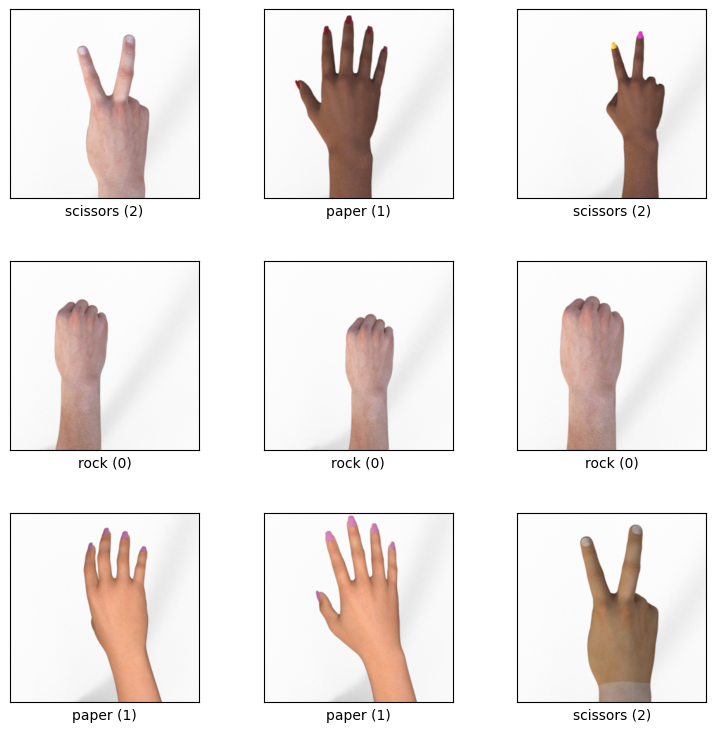

In [ ]:
fig = tfds.show_examples(dataset_test, ds_info)

### Parameters

In [ ]:
batch_size = 32
n_epochs = 8

### Preprocessing

In [ ]:
# Preprocessing for validation and test (no augmentation)
def preprocess(image, label):
    image = tf.image.resize(image, (32, 32))
    image = tf.image.rgb_to_grayscale(image)
    image = tf.cast(image, tf.float32) / 255.0
    return image, label

# Preprocessing for training (with augmentation)
def preprocess_train(image, label):
    image = tf.image.resize(image, (32, 32))
    image = tf.image.rgb_to_grayscale(image)
    image = tf.cast(image, tf.float32) / 255.0

    # Random brightness and contrast to simulate different lighting
    image = tf.image.random_brightness(image, max_delta=0.4)
    image = tf.image.random_contrast(image, lower=0.3, upper=1.7)

    # Random flip
    image = tf.image.random_flip_left_right(image)

    # Randomly invert the image (makes model robust to dark hand on light
    # background AND light hand on dark background)
    if tf.random.uniform(()) > 0.5:
        image = 1.0 - image

    # Add gaussian noise to simulate camera sensor noise
    noise = tf.random.normal(shape=tf.shape(image), mean=0.0, stddev=0.08)
    image = image + noise

    # Clip to valid range
    image = tf.clip_by_value(image, 0.0, 1.0)
    return image, label

In [ ]:
# Apply preprocessing — train uses augmentation, val/test do not
dataset_train = (dataset_train
                 .map(preprocess_train)
                 .shuffle(1000)
                 .batch(batch_size)
                 .prefetch(tf.data.AUTOTUNE))

dataset_val = (dataset_val
                .map(preprocess)
                .batch(batch_size)
                .prefetch(tf.data.AUTOTUNE))

dataset_test = (dataset_test
                .map(preprocess)
                .batch(batch_size)
                .prefetch(tf.data.AUTOTUNE))

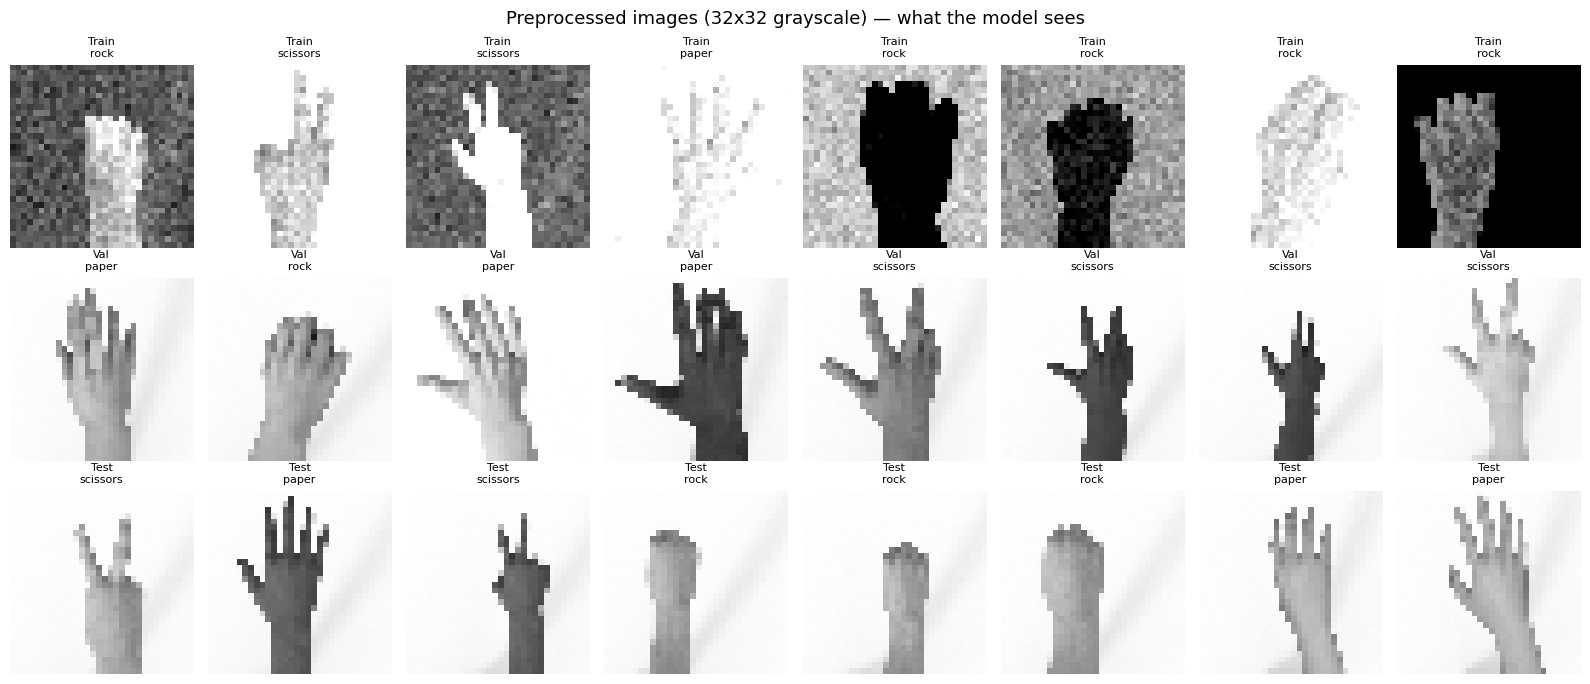

=== Pixel value statistics after preprocessing ===
Train: min=0.000  max=1.000  mean=0.475  shape=(32, 32, 32, 1)
Val: min=0.092  max=1.000  mean=0.828  shape=(32, 32, 32, 1)
Test: min=0.174  max=0.999  mean=0.883  shape=(32, 32, 32, 1)


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(3, 8, figsize=(16, 7))
fig.suptitle("Preprocessed images (32x32 grayscale) — what the model sees", fontsize=13)

split_names = ['Train', 'Val', 'Test']
splits = [dataset_train, dataset_val, dataset_test]
class_names = ['rock', 'paper', 'scissors']

for row, (name, ds) in enumerate(zip(split_names, splits)):
    for batch_images, batch_labels in ds.take(1):
        images = batch_images.numpy()   # convert entire batch to numpy first
        labels = batch_labels.numpy()   # then index into numpy array

        for col in range(8):
            ax = axes[row, col]
            img = images[col]           # shape: (32, 32, 1)
            label = int(labels[col])    # now safe to index

            ax.imshow(img.squeeze(), cmap='gray', vmin=0, vmax=1)
            ax.set_title(f"{name}\n{class_names[label]}", fontsize=8)
            ax.axis('off')

plt.tight_layout()
plt.show()

print("=== Pixel value statistics after preprocessing ===")
for name, ds in zip(split_names, splits):
    for batch_images, _ in ds.take(1):
        arr = batch_images.numpy()
        print(f"{name}: min={arr.min():.3f}  max={arr.max():.3f}  mean={arr.mean():.3f}  shape={arr.shape}")
        break

## Training Neural Network

In [ ]:
# Train longer with a lower learning rate for better generalization
n_epochs = 15  # more epochs to compensate for harder augmented training

model = keras.Sequential([
    keras.layers.Conv2D(8, (3, 3), activation='relu', input_shape=(32, 32, 1)),
    keras.layers.MaxPooling2D(2, 2),

    keras.layers.Conv2D(16, (3, 3), activation='relu'),
    keras.layers.MaxPooling2D(2, 2),

    keras.layers.Conv2D(32, (3, 3), activation='relu'),
    keras.layers.MaxPooling2D(2, 2),

    keras.layers.Flatten(),
    keras.layers.Dense(128, activation='relu'),
    keras.layers.Dropout(0.3),   # dropout helps generalization
    keras.layers.Dense(3, activation='softmax')
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0005),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (None, 30, 30, 8)         80        
                                                                 
 max_pooling2d (MaxPooling2  (None, 15, 15, 8)         0         
 D)                                                              
                                                                 
 conv2d_1 (Conv2D)           (None, 13, 13, 16)        1168      
                                                                 
 max_pooling2d_1 (MaxPoolin  (None, 6, 6, 16)          0         
 g2D)                                                            
                                                                 
 conv2d_2 (Conv2D)           (None, 4, 4, 32)          4640      
                                                                 
 max_pooling2d_2 (MaxPoolin  (None, 2, 2, 32)          0

In [ ]:
history = model.fit(
    dataset_train,
    validation_data=dataset_val,
    epochs=n_epochs
)

Epoch 1/15
71/71 [==============================] - 11s 44ms/step - loss: 1.0735 - accuracy: 0.4321 - val_loss: 0.9999 - val_accuracy: 0.5913
Epoch 2/15
71/71 [==============================] - 5s 43ms/step - loss: 0.8975 - accuracy: 0.6133 - val_loss: 0.5917 - val_accuracy: 0.8452
Epoch 3/15
71/71 [==============================] - 5s 34ms/step - loss: 0.6169 - accuracy: 0.7637 - val_loss: 0.3348 - val_accuracy: 0.8690
Epoch 4/15
71/71 [==============================] - 4s 34ms/step - loss: 0.4270 - accuracy: 0.8329 - val_loss: 0.2190 - val_accuracy: 0.9444
Epoch 5/15
71/71 [==============================] - 5s 51ms/step - loss: 0.3565 - accuracy: 0.8611 - val_loss: 0.1800 - val_accuracy: 0.9563
Epoch 6/15
71/71 [==============================] - 4s 37ms/step - loss: 0.3009 - accuracy: 0.8867 - val_loss: 0.1576 - val_accuracy: 0.9405
Epoch 7/15
71/71 [==============================] - 5s 44ms/step - loss: 0.2808 - accuracy: 0.8981 - val_loss: 0.1596 - val_accuracy: 0.9563
Epoch 8/15
7

In [ ]:
test_loss, baseline_accuracy = model.evaluate(
    dataset_test, verbose=0)

print(f'Test loss: {test_loss:.4f}')
print('Baseline test accuracy:', baseline_accuracy)

Test loss: 0.1971
Baseline test accuracy: 0.9220430254936218


In [ ]:
# Saving the model in .h5 format
keras.models.save_model(model, './Full_Precision_RPS.h5', include_optimizer=False)


/tmp/ipykernel_1484/2839357759.py:2: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native TF-Keras format, e.g. `model.save('my_model.keras')`.
  keras.models.save_model(model, './Full_Precision_RPS.h5', include_optimizer=False)


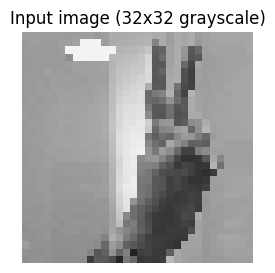

=== BEFORE pruning/quantization (full precision) ===
  rock: 0.0261
  paper: 0.1443
  scissors: 0.8296
>>> Predicted: scissors


/usr/local/lib/python3.12/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


In [ ]:
# ---------------------------------------------------------------
# Inference test — BEFORE pruning/quantization (full precision)
# ---------------------------------------------------------------
from PIL import Image as PILImage

img_path = 'captured_sample.png'  # change to your image
img = np.array(PILImage.open(img_path).convert('L'), dtype=np.uint8)
classes = ['rock', 'paper', 'scissors']

# Show the image
plt.figure(figsize=(3, 3))
plt.imshow(img, cmap='gray', vmin=0, vmax=255)
plt.title("Input image (32x32 grayscale)")
plt.axis('off')
plt.show()

# Convert full precision .h5 to tflite on the fly
converter = tf.lite.TFLiteConverter.from_keras_model(model)
tflite_fp = converter.convert()
with open('rps_test_fp.tflite', 'wb') as f:
    f.write(tflite_fp)

interp = tf.lite.Interpreter(model_path='rps_test_fp.tflite')
interp.allocate_tensors()
inp = interp.get_input_details()[0]
out = interp.get_output_details()[0]

input_data = (img.reshape(inp['shape']).astype(np.float32)) / 255.0
interp.set_tensor(inp['index'], input_data)
interp.invoke()
scores = interp.get_tensor(out['index'])[0]

print("=== BEFORE pruning/quantization (full precision) ===")
for cls, score in zip(classes, scores):
    print(f"  {cls}: {score:.4f}")
print(f">>> Predicted: {classes[int(np.argmax(scores))]}")

In this notebook, we trained a convolutional neural network on the rock-paper-scissors dataset using TensorFlow (and various of its APIs). It's important to note the size of the trained model in terms of the number of trainable parameters and the baseline test accuracy for further comparisons during the pruning and quantization steps.

## Pruning
Experiment with different pruning methods available in tensorflow_model_optimization library and track the test set accuracy and model size.

In [ ]:
import tensorflow_model_optimization as tfmot
prune_low_magnitude = tfmot.sparsity.keras.prune_low_magnitude

# Compute end step for the pruning schedule
num_train_images = ds_info.splits['train'].num_examples * 0.9
end_step = np.ceil(num_train_images / batch_size).astype(np.int32) * n_epochs
print(f"end_step = {end_step}")


end_step = 1065


### Task 1A: apply PolynomialDecay Pruning Schedule on the whole model.

In [ ]:
# Task 1A: PolynomialDecay pruning applied to the whole model
pruning_params = {
    'pruning_schedule': tfmot.sparsity.keras.PolynomialDecay(
        initial_sparsity=0.0,
        final_sparsity=0.5,
        begin_step=0,
        end_step=end_step
    )
}

base_model = keras.models.load_model('./Full_Precision_RPS.h5')

model_for_pruning = prune_low_magnitude(base_model, **pruning_params)

model_for_pruning.compile(
    optimizer='adam',
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=False),
    metrics=['accuracy']
)

callbacks = [tfmot.sparsity.keras.UpdatePruningStep()]

model_for_pruning.fit(
    dataset_train,
    validation_data=dataset_val,
    epochs=n_epochs,
    callbacks=callbacks
)

model_pruned_full = tfmot.sparsity.keras.strip_pruning(model_for_pruning)

# Recompile after strip_pruning (lost compile state)
model_pruned_full.compile(
    optimizer='adam',
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=False),
    metrics=['accuracy']
)

_, pruned_acc = model_pruned_full.evaluate(dataset_test, verbose=0)
print('Full-model pruned test accuracy:', pruned_acc)

keras.models.save_model(model_pruned_full, './Pruned_Full_RPS.h5', include_optimizer=False)

Epoch 1/15
71/71 [==============================] - 17s 39ms/step - loss: 0.1558 - accuracy: 0.9392 - val_loss: 0.0649 - val_accuracy: 0.9802
Epoch 2/15
71/71 [==============================] - 10s 116ms/step - loss: 0.1587 - accuracy: 0.9356 - val_loss: 0.0418 - val_accuracy: 0.9921
Epoch 3/15
71/71 [==============================] - 4s 38ms/step - loss: 0.1430 - accuracy: 0.9392 - val_loss: 0.0521 - val_accuracy: 0.9841
Epoch 4/15
71/71 [==============================] - 7s 83ms/step - loss: 0.1274 - accuracy: 0.9519 - val_loss: 0.0323 - val_accuracy: 0.9921
Epoch 5/15
71/71 [==============================] - 4s 38ms/step - loss: 0.1238 - accuracy: 0.9506 - val_loss: 0.0320 - val_accuracy: 0.9960
Epoch 6/15
71/71 [==============================] - 6s 49ms/step - loss: 0.1245 - accuracy: 0.9497 - val_loss: 0.0249 - val_accuracy: 0.9960
Epoch 7/15
71/71 [==============================] - 4s 38ms/step - loss: 0.1015 - accuracy: 0.9652 - val_loss: 0.0223 - val_accuracy: 0.9921
Epoch 8/15

/tmp/ipykernel_1484/1672761159.py:42: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native TF-Keras format, e.g. `model.save('my_model.keras')`.
  keras.models.save_model(model_pruned_full, './Pruned_Full_RPS.h5', include_optimizer=False)


### Task 1B: apply layerwise pruning only to the conv2D layers.

In [ ]:
# Task 1B: apply pruning only to Conv2D layers (layerwise)
def apply_pruning_to_conv2d(layer):
    if isinstance(layer, keras.layers.Conv2D):
        return prune_low_magnitude(
            layer,
            pruning_schedule=tfmot.sparsity.keras.ConstantSparsity(
                target_sparsity=0.5,
                begin_step=0
            )
        )
    return layer

base_model = keras.models.load_model('./Full_Precision_RPS.h5')

model_layerwise = keras.models.clone_model(
    base_model,
    clone_function=apply_pruning_to_conv2d
)

model_layerwise.compile(
    optimizer='adam',
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=False),
    metrics=['accuracy']
)

callbacks = [tfmot.sparsity.keras.UpdatePruningStep()]

model_layerwise.fit(
    dataset_train,
    validation_data=dataset_val,
    epochs=n_epochs,
    callbacks=callbacks
)

model_layerwise_stripped = tfmot.sparsity.keras.strip_pruning(model_layerwise)

# Recompile after strip_pruning (lost compile state)
model_layerwise_stripped.compile(
    optimizer='adam',
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=False),
    metrics=['accuracy']
)

_, layerwise_acc = model_layerwise_stripped.evaluate(dataset_test, verbose=0)
print('Conv2D-only pruned test accuracy:', layerwise_acc)

keras.models.save_model(model_layerwise_stripped, './Pruned_Conv2D_RPS.h5', include_optimizer=False)

Epoch 1/15
71/71 [==============================] - 8s 37ms/step - loss: 0.1786 - accuracy: 0.9259 - val_loss: 0.0445 - val_accuracy: 0.9960
Epoch 2/15
71/71 [==============================] - 5s 52ms/step - loss: 0.3213 - accuracy: 0.8907 - val_loss: 0.0972 - val_accuracy: 0.9802
Epoch 3/15
71/71 [==============================] - 4s 36ms/step - loss: 0.2022 - accuracy: 0.9286 - val_loss: 0.0898 - val_accuracy: 0.9683
Epoch 4/15
71/71 [==============================] - 4s 36ms/step - loss: 0.1874 - accuracy: 0.9268 - val_loss: 0.0429 - val_accuracy: 0.9960
Epoch 5/15
71/71 [==============================] - 6s 55ms/step - loss: 0.1700 - accuracy: 0.9334 - val_loss: 0.0461 - val_accuracy: 0.9881
Epoch 6/15
71/71 [==============================] - 4s 36ms/step - loss: 0.1637 - accuracy: 0.9374 - val_loss: 0.0332 - val_accuracy: 0.9960
Epoch 7/15
71/71 [==============================] - 4s 39ms/step - loss: 0.1520 - accuracy: 0.9369 - val_loss: 0.0466 - val_accuracy: 0.9921
Epoch 8/15
71

/tmp/ipykernel_1484/2260464816.py:47: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native TF-Keras format, e.g. `model.save('my_model.keras')`.
  keras.models.save_model(model_layerwise_stripped, './Pruned_Conv2D_RPS.h5', include_optimizer=False)


For both tasks try different sparsity parameters.

## Quantization
Quantization helps reduce the size and computation requirements of models, making them more efficient, especially for deployment on resource-constrained devices. Here, we only experiment with post-training quantization methods.

The following post-training quantization can be applied to both the base model and the pruned model. Note: all the following tasks will produce different versions of the same model.

Helper for tasks 2B and 2C — representative dataset for calibrating activations during integer quantization.

In [ ]:
# Representative dataset used by integer quantization to calibrate activation ranges
def representative_dataset():
    # Take ~100 samples from the training set
    for image, _ in dataset_train.unbatch().take(100):
        yield [tf.expand_dims(image, axis=0)]

# Pick the model you want to deploy. Options:
#   keras.models.load_model('./Full_Precision_RPS.h5')      # baseline
#   keras.models.load_model('./Pruned_Full_RPS.h5')         # Task 1A
#   keras.models.load_model('./Pruned_Conv2D_RPS.h5')       # Task 1B
model_to_convert = keras.models.load_model('./Full_Precision_RPS.h5')


### Task 2A: Dynamic Range Quantization

In [ ]:
# Task 2A: Dynamic Range Quantization
# Weights -> int8, activations kept as float at runtime.
converter = tf.lite.TFLiteConverter.from_keras_model(model_to_convert)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
tflite_dynamic = converter.convert()

with open('rps_dynamic_quant.tflite', 'wb') as f:
    f.write(tflite_dynamic)

print(f'Dynamic-range quantized model size: {len(tflite_dynamic):,} bytes')


Dynamic-range quantized model size: 30,840 bytes


### Task 2B: Integer quantization of model parameters with float input/outputs (needs representative dataset)

In [ ]:
# Task 2B: Integer quantization of weights AND activations,
# but input/output stay as float32 (TFLite inserts quantize/dequantize ops).
converter = tf.lite.TFLiteConverter.from_keras_model(model_to_convert)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
converter.representative_dataset = representative_dataset
tflite_int_float_io = converter.convert()

with open('rps_int_quant_float_io.tflite', 'wb') as f:
    f.write(tflite_int_float_io)

print(f'Integer quant (float I/O) model size: {len(tflite_int_float_io):,} bytes')


/usr/local/lib/python3.12/dist-packages/tensorflow/lite/python/convert.py:863: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(


Integer quant (float I/O) model size: 32,720 bytes


### Task 2C: Full integer quantization (needs representative dataset)

In [ ]:
# Task 2C: Full integer quantization with uint8 input and uint8 output.
# This is the version to deploy on Arduino Nano 33 BLE Sense.
converter = tf.lite.TFLiteConverter.from_keras_model(model_to_convert)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
converter.representative_dataset = representative_dataset
converter.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
converter.inference_input_type = tf.uint8
converter.inference_output_type = tf.uint8
tflite_full_int = converter.convert()

with open('rps_full_int_quant.tflite', 'wb') as f:
    f.write(tflite_full_int)

print(f'Full integer quant model size: {len(tflite_full_int):,} bytes')


/usr/local/lib/python3.12/dist-packages/tensorflow/lite/python/convert.py:863: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(


Full integer quant model size: 32,736 bytes


Verify each case with the following code:

In [ ]:
# Verify the model's input/output types. For Arduino deployment with the
# camera script, both should print: <class 'numpy.uint8'>
interpreter = tf.lite.Interpreter(model_path='rps_full_int_quant.tflite')
input_details = interpreter.get_input_details()
output_details = interpreter.get_output_details()

print('Input type :', input_details[0]['dtype'])
print('Input shape:', input_details[0]['shape'])
print('Output type:', output_details[0]['dtype'])
print('Output shape:', output_details[0]['shape'])


Input type : <class 'numpy.uint8'>
Input shape: [ 1 32 32  1]
Output type: <class 'numpy.uint8'>
Output shape: [1 3]


/usr/local/lib/python3.12/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


## Compare Compression Combinations

In [ ]:
# Helper: evaluate any .tflite model on the test set
def evaluate_tflite_model(tflite_path, dataset):
    """Run the test set through a .tflite model and return accuracy."""
    interpreter = tf.lite.Interpreter(model_path=tflite_path)
    interpreter.allocate_tensors()
    in_det  = interpreter.get_input_details()[0]
    out_det = interpreter.get_output_details()[0]

    correct, total = 0, 0
    for batch_images, batch_labels in dataset:
        imgs   = batch_images.numpy()
        labels = batch_labels.numpy()
        for i in range(len(imgs)):
            img = imgs[i]  # shape (32, 32, 1), float32 in [0, 1]

            if in_det['dtype'] == np.uint8:
                # Quantize float [0,1] -> uint8 [0,255] for full-int models
                x = (img * 255.0).astype(np.uint8)
            else:
                x = img.astype(np.float32)

            interpreter.set_tensor(in_det['index'], np.expand_dims(x, axis=0))
            interpreter.invoke()
            scores = interpreter.get_tensor(out_det['index'])[0]

            if int(np.argmax(scores)) == int(labels[i]):
                correct += 1
            total += 1
    return correct / total


In [ ]:
# Helper: apply full integer quantization (uint8 I/O) to any Keras model
def to_full_int8_tflite(keras_model, out_path):
    converter = tf.lite.TFLiteConverter.from_keras_model(keras_model)
    converter.optimizations = [tf.lite.Optimize.DEFAULT]
    converter.representative_dataset = representative_dataset
    converter.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
    converter.inference_input_type  = tf.uint8
    converter.inference_output_type = tf.uint8
    tflite_bytes = converter.convert()
    with open(out_path, 'wb') as f:
        f.write(tflite_bytes)
    return len(tflite_bytes)


### Build deployable variants and evaluate everything


In [ ]:
# Build the three deployable variants: baseline / pruned-full / pruned-conv2d,
# each followed by full integer quantization with uint8 I/O.
variants = {
    'baseline':       './Full_Precision_RPS.h5',
    'pruned_full':    './Pruned_Full_RPS.h5',
    'pruned_conv2d':  './Pruned_Conv2D_RPS.h5',
}

tflite_paths = {}
for name, h5_path in variants.items():
    m = keras.models.load_model(h5_path)
    out_tflite = f'rps_{name}_full_int8.tflite'
    size = to_full_int8_tflite(m, out_tflite)
    tflite_paths[name] = out_tflite
    print(f'{name:>20s}  ->  {out_tflite}  ({size:,} bytes)')


/usr/local/lib/python3.12/dist-packages/tensorflow/lite/python/convert.py:863: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(


            baseline  ->  rps_baseline_full_int8.tflite  (32,736 bytes)


/usr/local/lib/python3.12/dist-packages/tensorflow/lite/python/convert.py:863: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(


         pruned_full  ->  rps_pruned_full_full_int8.tflite  (32,736 bytes)


/usr/local/lib/python3.12/dist-packages/tensorflow/lite/python/convert.py:863: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(


       pruned_conv2d  ->  rps_pruned_conv2d_full_int8.tflite  (32,736 bytes)


In [ ]:
# Evaluate accuracy of every model variant we produced
results = []

# Full-precision Keras baseline (already trained above)
_, acc_fp = model.evaluate(dataset_test, verbose=0)
results.append(('baseline (float32 .h5)', os.path.getsize('./Full_Precision_RPS.h5'), acc_fp))

# Pruned Keras models
m_pf = keras.models.load_model('./Pruned_Full_RPS.h5')
m_pf.compile(optimizer='adam',
             loss=tf.keras.losses.SparseCategoricalCrossentropy(),
             metrics=['accuracy'])
_, acc_pf = m_pf.evaluate(dataset_test, verbose=0)
results.append(('pruned full-model (float32 .h5)',
                os.path.getsize('./Pruned_Full_RPS.h5'), acc_pf))

m_pc = keras.models.load_model('./Pruned_Conv2D_RPS.h5')
m_pc.compile(optimizer='adam',
             loss=tf.keras.losses.SparseCategoricalCrossentropy(),
             metrics=['accuracy'])
_, acc_pc = m_pc.evaluate(dataset_test, verbose=0)
results.append(('pruned conv2d-only (float32 .h5)',
                os.path.getsize('./Pruned_Conv2D_RPS.h5'), acc_pc))

# Baseline + each quantization scheme (.tflite files produced earlier)
for label, path in [
    ('baseline + dynamic range quant',     'rps_dynamic_quant.tflite'),
    ('baseline + int quant (float I/O)',   'rps_int_quant_float_io.tflite'),
    ('baseline + full int quant (uint8)',  'rps_full_int_quant.tflite'),
]:
    acc = evaluate_tflite_model(path, dataset_test)
    results.append((label, os.path.getsize(path), acc))

# Pruned + full int8 (the new combinations)
for name in ['pruned_full', 'pruned_conv2d']:
    path = tflite_paths[name]
    acc = evaluate_tflite_model(path, dataset_test)
    results.append((f'{name} + full int quant (uint8)',
                    os.path.getsize(path), acc))

# Print a comparison table
print(f"{'Variant':<42s}{'Size (bytes)':>14s}{'Test acc':>12s}")
print('-' * 68)
for name, size, acc in results:
    print(f"{name:<42s}{size:>14,}{acc:>12.4f}")


/usr/local/lib/python3.12/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


Variant                                     Size (bytes)    Test acc
--------------------------------------------------------------------
baseline (float32 .h5)                           122,736      0.9220
pruned full-model (float32 .h5)                  122,736      0.9113
pruned conv2d-only (float32 .h5)                 122,736      0.8575
baseline + dynamic range quant                    30,840      0.9220
baseline + int quant (float I/O)                  32,720      0.9247
baseline + full int quant (uint8)                 32,736      0.9247
pruned_full + full int quant (uint8)              32,736      0.9086
pruned_conv2d + full int quant (uint8)            32,736      0.8468


### Generate one model.h per variant


In [ ]:
# Helper: convert a .tflite file to a C header named model.h-style.
# The variable is always called 'model' so the Arduino sketch needs no edits.
def tflite_to_header(tflite_path, header_path):
    with open(tflite_path, 'rb') as f:
        data = f.read()
    with open(header_path, 'w') as f:
        f.write('const unsigned char model[] = {\n')
        for i in range(0, len(data), 12):
            chunk = data[i:i + 12]
            line = ', '.join(f'0x{b:02x}' for b in chunk)
            f.write('  ' + line)
            if i + 12 < len(data):
                f.write(',')
            f.write('\n')
        f.write('};\n')
        f.write(f'const unsigned int model_len = {len(data)};\n')
    return os.path.getsize(header_path)


In [ ]:
# Generate one .h file per deployable variant
header_paths = {}
for name, tflite_path in tflite_paths.items():
    h_path = f'model_{name}.h'
    size = tflite_to_header(tflite_path, h_path)
    header_paths[name] = h_path
    print(f'{h_path}  ({size:,} bytes)')


model_baseline.h  (201,944 bytes)
model_pruned_full.h  (201,944 bytes)
model_pruned_conv2d.h  (201,944 bytes)


### Download all headers as a zip


In [ ]:
# Zip the three .h files and download them together
import zipfile
zip_path = 'model_headers.zip'
with zipfile.ZipFile(zip_path, 'w') as zf:
    for path in header_paths.values():
        zf.write(path)
print(f'Created {zip_path} with {len(header_paths)} headers')

# In Colab: download the zip directly to your computer
from google.colab import files
files.download(zip_path)


Created model_headers.zip with 3 headers


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>